In [ ]:
# Install required packages
!pip install factor_analyzer openpyxl

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 kB 3.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for factor_analyzer: filename=factor_analyzer-0.5.1-py2.py3-none-any.whl size=42655 sha256=5baca6afe0bdf0884b10837fef804a8772b83e48a5c48fc35cc7cde5a0a802bb
  Stored in directory: /root/.cache/pip/wheels/87/6e/8f/914f20e0242ee0214e5c8336031a2fab12e632e4695fbb7276
Successfully built factor_analyzer


In [ ]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.stats import pearsonr
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity

import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [ ]:
# Upload the Excel dataset

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_excel(file_name)

print("Data successfully loaded.")
print("Dataset shape:", df.shape)

Saving Motorola_Data.xlsx to Motorola_Data.xlsx
Data successfully loaded.
Dataset shape: (60, 12)


In [ ]:
# Display the first five rows

df.head()

,Quarter,Current Ratio,Debt-to-Equity Ratio,Long-term Debt-to-Capital,Asset Turnover,Inventory Turnover,Receivable Turnover,Gross Margin,Operating Margin,Net Profit Margin,ROA,ROE
0,Q3 2011,2.3303,0.3480,0.1998,0.1412,1.8796,1.3583,50.5995,12.1823,6.1391,1.0494,2.5171
1,Q4 2011,2.2983,0.2911,0.1765,0.1651,2.2266,1.2326,50.4348,12.0000,8.0000,1.2277,3.2423
2,Q1 2012,2.0589,0.3723,0.2150,0.1572,2.0870,1.1392,49.7444,11.8609,8.0266,1.2778,3.8686
3,Q2 2012,2.4157,0.4815,0.3246,0.1762,2.2295,1.3509,49.3482,12.9423,8.4730,1.4517,4.5701
4,Q3 2012,2.3267,0.4783,0.3231,0.1791,1.9814,1.2635,50.4877,15.0488,9.5680,1.7138,5.2861


In [ ]:
df = pd.read_excel(file_name)
df = pd.read_excel(file_name)

In [ ]:
# Check column names and data types

print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Column names:
['Quarter', 'Current Ratio', 'Debt-to-Equity Ratio', 'Long-term Debt-to-Capital', 'Asset Turnover', 'Inventory Turnover', 'Receivable Turnover', 'Gross Margin', 'Operating Margin', 'Net Profit Margin', 'ROA', 'ROE']

Data types:
Quarter                       object
Current Ratio                float64
Debt-to-Equity Ratio         float64
Long-term Debt-to-Capital    float64
Asset Turnover               float64
Inventory Turnover           float64
Receivable Turnover          float64
Gross Margin                 float64
Operating Margin             float64
Net Profit Margin            float64
ROA                          float64
ROE                          float64
dtype: object


In [ ]:
print("Number of observations:", df.shape[0])
print("Number of variables:", df.shape[1])

Number of observations: 60
Number of variables: 12


In [ ]:
# Select the 11 financial ratios for the analysis

variables = [
    "Current Ratio",
    "Debt-to-Equity Ratio",
    "Long-term Debt-to-Capital",
    "Asset Turnover",
    "Inventory Turnover",
    "Receivable Turnover",
    "Gross Margin",
    "Operating Margin",
    "Net Profit Margin",
    "ROA",
    "ROE"
]

data = df[variables].copy()

print("Number of financial ratios:", len(variables))
print("Analysis dataset shape:", data.shape)

Number of financial ratios: 11
Analysis dataset shape: (60, 11)


In [ ]:
# Display the selected financial ratios

data.head()

,Current Ratio,Debt-to-Equity Ratio,Long-term Debt-to-Capital,Asset Turnover,Inventory Turnover,Receivable Turnover,Gross Margin,Operating Margin,Net Profit Margin,ROA,ROE
0,2.3303,0.3480,0.1998,0.1412,1.8796,1.3583,50.5995,12.1823,6.1391,1.0494,2.5171
1,2.2983,0.2911,0.1765,0.1651,2.2266,1.2326,50.4348,12.0000,8.0000,1.2277,3.2423
2,2.0589,0.3723,0.2150,0.1572,2.0870,1.1392,49.7444,11.8609,8.0266,1.2778,3.8686
3,2.4157,0.4815,0.3246,0.1762,2.2295,1.3509,49.3482,12.9423,8.4730,1.4517,4.5701
4,2.3267,0.4783,0.3231,0.1791,1.9814,1.2635,50.4877,15.0488,9.5680,1.7138,5.2861


In [ ]:
# Check for missing values

missing_values = data.isnull().sum()

print("Missing values in each variable:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each variable:
Current Ratio                0
Debt-to-Equity Ratio         0
Long-term Debt-to-Capital    0
Asset Turnover               0
Inventory Turnover           0
Receivable Turnover          0
Gross Margin                 0
Operating Margin             0
Net Profit Margin            0
ROA                          0
ROE                          0
dtype: int64

Total missing values: 0


In [ ]:
if missing_values.sum() == 0:
    print("There are no missing values in the selected variables.")
else:
    print("Missing values are present and should be reviewed.")

There are no missing values in the selected variables.


In [ ]:
# Check for duplicate observations

duplicate_count = data.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [ ]:
duplicates = data[data.duplicated(keep=False)]
print(duplicates)

Empty DataFrame
Columns: [Current Ratio, Debt-to-Equity Ratio, Long-term Debt-to-Capital, Asset Turnover, Inventory Turnover, Receivable Turnover, Gross Margin, Operating Margin, Net Profit Margin, ROA, ROE]
Index: []


In [ ]:
# Check for duplicate quarters

if "Quarter" in df.columns:
    print("Duplicate quarters:", df["Quarter"].duplicated().sum())

Duplicate quarters: 0


In [ ]:
# Check for potential outliers using the IQR method

outlier_summary = {}

for col in variables:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = ((data[col] < lower_bound) |
                (data[col] > upper_bound)).sum()

    outlier_summary[col] = outliers

outlier_summary = pd.Series(outlier_summary, name="Potential Outliers")

outlier_summary

,Potential Outliers
Current Ratio,0
Debt-to-Equity Ratio,7
Long-term Debt-to-Capital,0
Asset Turnover,2
Inventory Turnover,1
Receivable Turnover,1
Gross Margin,1
Operating Margin,1
Net Profit Margin,2
ROA,2


In [ ]:
# Calculate descriptive statistics

descriptive_statistics = pd.DataFrame({
    "Mean": data.mean(),
    "Standard Deviation": data.std(),
    "Minimum": data.min(),
    "Maximum": data.max()
})

descriptive_statistics.round(4)

,Mean,Standard Deviation,Minimum,Maximum
Current Ratio,1.6135,0.5782,0.9516,3.0573
Debt-to-Equity Ratio,-6.2161,34.0965,-247.5217,45.9084
Long-term Debt-to-Capital,0.8975,0.3560,0.1765,1.6415
Asset Turnover,67.2179,364.2097,0.1046,2062.0000
Inventory Turnover,1.9345,0.5584,1.0397,3.4945
Receivable Turnover,1.3953,0.2420,0.7111,1.7833
Gross Margin,48.9477,2.2651,42.0788,53.5589
Operating Margin,16.8993,13.7749,-79.9342,27.9290
Net Profit Margin,13.0523,9.6696,-29.3817,59.1529
ROA,1.9109,2.1416,-8.8842,4.6043


In [ ]:
# Standardize the financial ratios

scaler = StandardScaler()

standardized_data = scaler.fit_transform(data)

standardized_data = pd.DataFrame(
    standardized_data,
    columns=variables
)

standardized_data.head()

,Current Ratio,Debt-to-Equity Ratio,Long-term Debt-to-Capital,Asset Turnover,Inventory Turnover,Receivable Turnover,Gross Margin,Operating Margin,Net Profit Margin,ROA,ROE
0,1.2502,0.1941,-1.9765,-0.1857,-0.0991,-0.1542,0.7354,-0.3453,-0.7210,-0.4057,0.0558
1,1.1944,0.1925,-2.0425,-0.1857,0.5276,-0.6781,0.6621,-0.3587,-0.5269,-0.3217,0.0584
2,0.7768,0.1949,-1.9334,-0.1857,0.2755,-1.0673,0.3547,-0.3689,-0.5241,-0.2981,0.0607
3,1.3991,0.1981,-1.6229,-0.1856,0.5329,-0.1851,0.1783,-0.2897,-0.4776,-0.2162,0.0632
4,1.2439,0.1980,-1.6272,-0.1856,0.0848,-0.5493,0.6856,-0.1355,-0.3634,-0.0928,0.0657


In [ ]:
# Check the mean and standard deviation after standardization

standardization_check = pd.DataFrame({
    "Mean": standardized_data.mean(),
    "Standard Deviation": standardized_data.std()
})

standardization_check.round(4)

,Mean,Standard Deviation
Current Ratio,-0.0000,1.0084
Debt-to-Equity Ratio,-0.0000,1.0084
Long-term Debt-to-Capital,-0.0000,1.0084
Asset Turnover,0.0000,1.0084
Inventory Turnover,-0.0000,1.0084
Receivable Turnover,-0.0000,1.0084
Gross Margin,-0.0000,1.0084
Operating Margin,0.0000,1.0084
Net Profit Margin,0.0000,1.0084
ROA,-0.0000,1.0084


In [ ]:
# Calculate the Pearson correlation matrix

pearson_corr = data.corr(method="pearson")

print("Pearson Correlation Matrix")
pearson_corr.round(4)

Pearson Correlation Matrix


,Current Ratio,Debt-to-Equity Ratio,Long-term Debt-to-Capital,Asset Turnover,Inventory Turnover,Receivable Turnover,Gross Margin,Operating Margin,Net Profit Margin,ROA,ROE
Current Ratio,1.0000,0.0223,-0.6748,-0.1159,0.2241,-0.6745,-0.1024,-0.4998,0.0124,-0.4154,-0.0315
Debt-to-Equity Ratio,0.0223,1.0000,-0.1321,0.0898,-0.0317,-0.0995,0.0292,-0.0334,0.0072,-0.0436,0.8837
Long-term Debt-to-Capital,-0.6748,-0.1321,1.0000,-0.0228,0.2671,0.4616,-0.3092,0.2206,-0.3045,0.0425,-0.0641
Asset Turnover,-0.1159,0.0898,-0.0228,1.0000,-0.1260,0.1310,0.1266,0.1015,0.0944,0.1506,0.3795
Inventory Turnover,0.2241,-0.0317,0.2671,-0.1260,1.0000,-0.1217,-0.0638,-0.1675,-0.2125,-0.2753,-0.0869
Receivable Turnover,-0.6745,-0.0995,0.4616,0.1310,-0.1217,1.0000,0.1512,0.2437,0.0722,0.3506,-0.0405
Gross Margin,-0.1024,0.0292,-0.3092,0.1266,-0.0638,0.1512,1.0000,0.2064,0.2244,0.1983,-0.0249
Operating Margin,-0.4998,-0.0334,0.2206,0.1015,-0.1675,0.2437,0.2064,1.0000,0.0735,0.7240,0.0063
Net Profit Margin,0.0124,0.0072,-0.3045,0.0944,-0.2125,0.0722,0.2244,0.0735,1.0000,0.5007,-0.0011
ROA,-0.4154,-0.0436,0.0425,0.1506,-0.2753,0.3506,0.1983,0.7240,0.5007,1.0000,0.0010


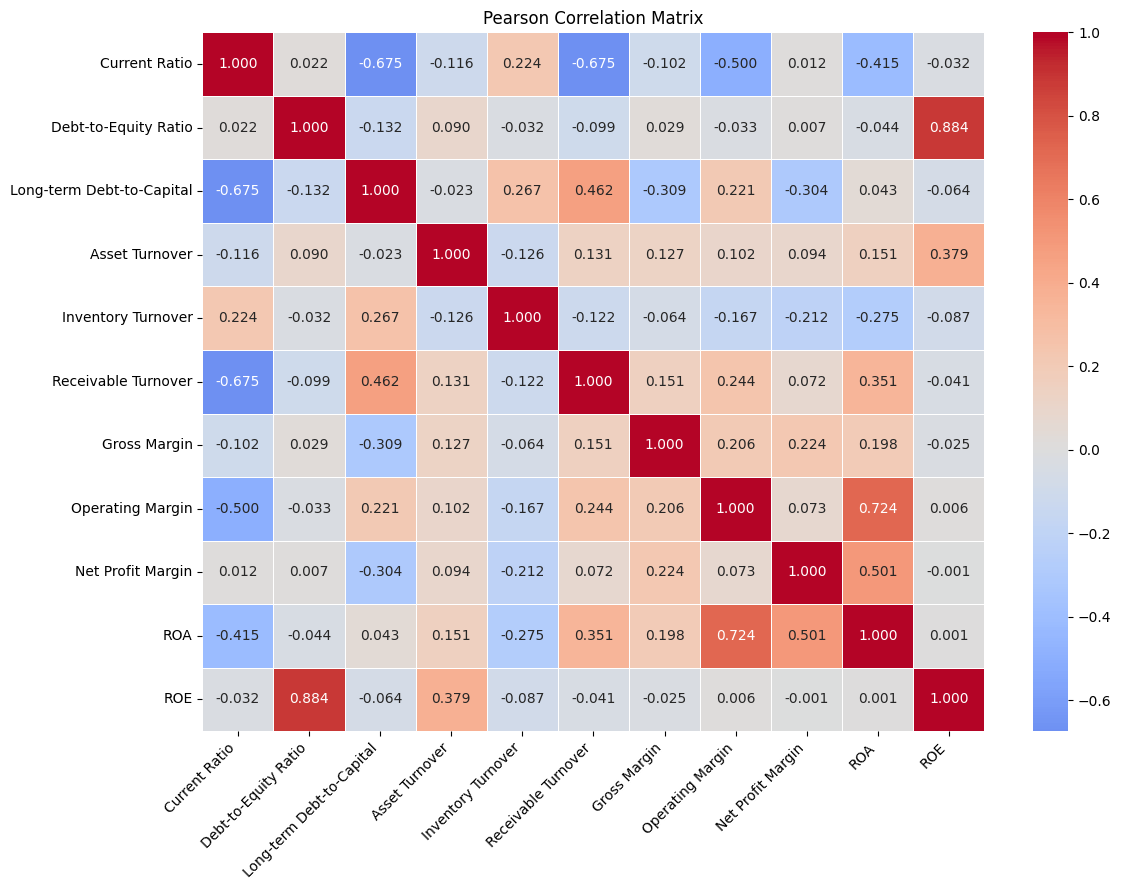

In [ ]:
# Visualize the Pearson correlation matrix

plt.figure(figsize=(12, 9))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Pearson Correlation Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Perform Bartlett's test of sphericity

bartlett_chi_square, bartlett_p_value = calculate_bartlett_sphericity(
    standardized_data
)

print("Bartlett's Test of Sphericity")
print(f"Chi-square: {bartlett_chi_square:.4f}")
print(f"p-value: {bartlett_p_value:.4e}")

Bartlett's Test of Sphericity
Chi-square: 349.3723
p-value: 2.0242e-44


In [ ]:
# Calculate the determinant of the correlation matrix

determinant = np.linalg.det(pearson_corr)

print(f"Determinant of correlation matrix: {determinant:.6f}")

Determinant of correlation matrix: 0.001644


In [ ]:
def calculate_kmo_msa(data, variables):
    """
    Calculate the overall KMO and individual MSA values.
    """

    selected_data = data[variables]

    kmo_all, kmo_model = calculate_kmo(selected_data)

    msa = pd.DataFrame({
        "Variable": variables,
        "MSA": kmo_all
    })

    return kmo_model, msa

In [ ]:
# Calculate KMO and MSA for the 11 financial ratios

kmo_value, msa_table = calculate_kmo_msa(
    standardized_data,
    variables
)

print(f"Overall KMO: {kmo_value:.4f}")

msa_table.round(4)

Overall KMO: 0.4471


,Variable,MSA
0,Current Ratio,0.5361
1,Debt-to-Equity Ratio,0.3887
2,Long-term Debt-to-Capital,0.4242
3,Asset Turnover,0.2405
4,Inventory Turnover,0.2646
5,Receivable Turnover,0.7193
6,Gross Margin,0.2808
7,Operating Margin,0.5052
8,Net Profit Margin,0.4298
9,ROA,0.5307


In [ ]:
# Remove Asset Turnover based on its MSA value

variables_step1 = [
    "Current Ratio",
    "Debt-to-Equity Ratio",
    "Long-term Debt-to-Capital",
    "Inventory Turnover",
    "Receivable Turnover",
    "Gross Margin",
    "Operating Margin",
    "Net Profit Margin",
    "ROA",
    "ROE"
]

kmo_step1, msa_step1 = calculate_kmo_msa(
    standardized_data,
    variables_step1
)

print(f"Overall KMO after removing Asset Turnover: {kmo_step1:.4f}")

msa_step1.round(4)

Overall KMO after removing Asset Turnover: 0.4761


,Variable,MSA
0,Current Ratio,0.5335
1,Debt-to-Equity Ratio,0.4824
2,Long-term Debt-to-Capital,0.4236
3,Inventory Turnover,0.2530
4,Receivable Turnover,0.7087
5,Gross Margin,0.2705
6,Operating Margin,0.5029
7,Net Profit Margin,0.4241
8,ROA,0.5250
9,ROE,0.4915


In [ ]:
# Remove Inventory Turnover based on its MSA value

variables_step2 = [
    "Current Ratio",
    "Debt-to-Equity Ratio",
    "Long-term Debt-to-Capital",
    "Receivable Turnover",
    "Gross Margin",
    "Operating Margin",
    "Net Profit Margin",
    "ROA",
    "ROE"
]

kmo_step2, msa_step2 = calculate_kmo_msa(
    standardized_data,
    variables_step2
)

print(f"Overall KMO after removing Inventory Turnover: {kmo_step2:.4f}")

msa_step2.round(4)

Overall KMO after removing Inventory Turnover: 0.5323


,Variable,MSA
0,Current Ratio,0.6628
1,Debt-to-Equity Ratio,0.5012
2,Long-term Debt-to-Capital,0.5733
3,Receivable Turnover,0.6685
4,Gross Margin,0.3663
5,Operating Margin,0.4889
6,Net Profit Margin,0.3941
7,ROA,0.5041
8,ROE,0.4968


In [ ]:
# Remove Gross Margin based on its MSA value

final_variables = [
    "Current Ratio",
    "Debt-to-Equity Ratio",
    "Long-term Debt-to-Capital",
    "Receivable Turnover",
    "Operating Margin",
    "Net Profit Margin",
    "ROA",
    "ROE"
]

kmo_step3, msa_step3 = calculate_kmo_msa(
    standardized_data,
    final_variables
)

print(f"Overall KMO after removing Gross Margin: {kmo_step3:.4f}")

msa_step3.round(4)

Overall KMO after removing Gross Margin: 0.5502


,Variable,MSA
0,Current Ratio,0.6555
1,Debt-to-Equity Ratio,0.4986
2,Long-term Debt-to-Capital,0.6584
3,Receivable Turnover,0.6767
4,Operating Margin,0.4949
5,Net Profit Margin,0.3608
6,ROA,0.5190
7,ROE,0.4994


In [ ]:
# Remove Net Profit Margin based on its MSA value

variables_step4 = [
    "Current Ratio",
    "Debt-to-Equity Ratio",
    "Long-term Debt-to-Capital",
    "Receivable Turnover",
    "Operating Margin",
    "ROA",
    "ROE"
]

kmo_step4, msa_step4 = calculate_kmo_msa(
    standardized_data,
    variables_step4
)

print(f"Overall KMO after removing Net Profit Margin: {kmo_step4:.4f}")

msa_step4.round(4)

Overall KMO after removing Net Profit Margin: 0.5826


,Variable,MSA
0,Current Ratio,0.6582
1,Debt-to-Equity Ratio,0.4976
2,Long-term Debt-to-Capital,0.6082
3,Receivable Turnover,0.6699
4,Operating Margin,0.5860
5,ROA,0.5607
6,ROE,0.4997


In [ ]:
# Remove Debt-to-Equity Ratio based on its MSA value

variables_step5 = [
    "Current Ratio",
    "Long-term Debt-to-Capital",
    "Receivable Turnover",
    "Operating Margin",
    "ROA",
    "ROE"
]

kmo_step5, msa_step5 = calculate_kmo_msa(
    standardized_data,
    variables_step5
)

print(f"Overall KMO after removing Debt-to-Equity Ratio: {kmo_step5:.4f}")

msa_step5.round(4)

Overall KMO after removing Debt-to-Equity Ratio: 0.6152


,Variable,MSA
0,Current Ratio,0.6573
1,Long-term Debt-to-Capital,0.6120
2,Receivable Turnover,0.6667
3,Operating Margin,0.5842
4,ROA,0.5618
5,ROE,0.1415


In [ ]:
# Remove ROE based on its MSA value

final_variables = [
    "Current Ratio",
    "Long-term Debt-to-Capital",
    "Receivable Turnover",
    "Operating Margin",
    "ROA"
]

kmo_final, msa_final = calculate_kmo_msa(
    standardized_data,
    final_variables
)

print(f"Final KMO: {kmo_final:.4f}")

msa_final.round(4)

Final KMO: 0.6229


,Variable,MSA
0,Current Ratio,0.6677
1,Long-term Debt-to-Capital,0.6222
2,Receivable Turnover,0.6703
3,Operating Margin,0.5837
4,ROA,0.5614


In [ ]:
# Create the final dataset using the five selected variables

final_data = data[final_variables].copy()

print("Final number of variables:", len(final_variables))
print("Final variables:")

for variable in final_variables:
    print("-", variable)

Final number of variables: 5
Final variables:
- Current Ratio
- Long-term Debt-to-Capital
- Receivable Turnover
- Operating Margin
- ROA


In [ ]:
# Standardize the final five variables for PCA

final_standardized = pd.DataFrame(
    scaler.fit_transform(final_data),
    columns=final_variables,
    index=final_data.index
)

final_standardized.head()

,Current Ratio,Long-term Debt-to-Capital,Receivable Turnover,Operating Margin,ROA
0,1.2502,-1.9765,-0.1542,-0.3453,-0.4057
1,1.1944,-2.0425,-0.6781,-0.3587,-0.3217
2,0.7768,-1.9334,-1.0673,-0.3689,-0.2981
3,1.3991,-1.6229,-0.1851,-0.2897,-0.2162
4,1.2439,-1.6272,-0.5493,-0.1355,-0.0928


In [ ]:
# Perform Bartlett's test of sphericity for the final variables

bartlett_chi_square_final, bartlett_p_value_final = calculate_bartlett_sphericity(
    final_standardized
)

print("Bartlett's Test of Sphericity")
print(f"Chi-square: {bartlett_chi_square_final:.4f}")
print(f"p-value: {bartlett_p_value_final:.4e}")

Bartlett's Test of Sphericity
Chi-square: 140.9030
p-value: 2.7521e-25


In [ ]:
# Calculate the Pearson correlation matrix for the final variables

final_corr = final_data.corr(method="pearson")

print("Pearson Correlation Matrix for Final Variables")

final_corr.round(4)

Pearson Correlation Matrix for Final Variables


,Current Ratio,Long-term Debt-to-Capital,Receivable Turnover,Operating Margin,ROA
Current Ratio,1.0000,-0.6748,-0.6745,-0.4998,-0.4154
Long-term Debt-to-Capital,-0.6748,1.0000,0.4616,0.2206,0.0425
Receivable Turnover,-0.6745,0.4616,1.0000,0.2437,0.3506
Operating Margin,-0.4998,0.2206,0.2437,1.0000,0.7240
ROA,-0.4154,0.0425,0.3506,0.7240,1.0000


In [ ]:
# Calculate the determinant of the final correlation matrix

determinant_final = np.linalg.det(final_corr)

print(f"Determinant of correlation matrix: {determinant_final:.6f}")

Determinant of correlation matrix: 0.082591


In [ ]:
# Perform Principal Component Analysis

pca = PCA()

pca_result = pca.fit_transform(final_standardized)

In [ ]:
# Extract eigenvalues and explained variance

eigenvalues = pca.explained_variance_

variance_explained = pca.explained_variance_ratio_ * 100

cumulative_variance = variance_explained.cumsum()

In [ ]:
# Create a summary table of the PCA results

pca_summary = pd.DataFrame({
    "Component": range(1, len(final_variables) + 1),
    "Eigenvalue": eigenvalues,
    "Variance Explained (%)": variance_explained,
    "Cumulative Variance (%)": cumulative_variance
})

pca_summary.round(4)

,Component,Eigenvalue,Variance Explained (%),Cumulative Variance (%)
0,1,2.8048,55.1619,55.1619
1,2,1.2792,25.1577,80.3195
2,3,0.5864,11.5324,91.8519
3,4,0.2219,4.3636,96.2155
4,5,0.1924,3.7845,100.0000


In [ ]:
# Retain components with eigenvalues greater than 1

retained_components = sum(eigenvalues > 1)

print("Number of retained components:", retained_components)

Number of retained components: 2


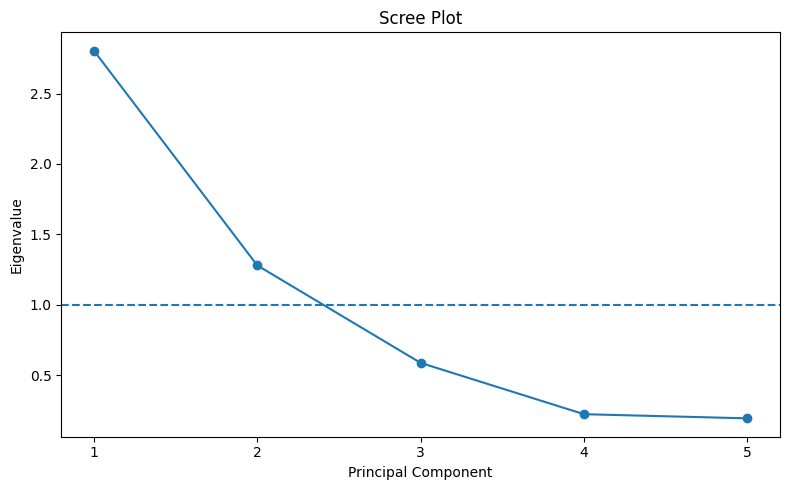

In [ ]:
# Create the scree plot

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(eigenvalues) + 1),
    eigenvalues,
    marker="o"
)

plt.axhline(
    y=1,
    linestyle="--"
)

plt.xlabel("Principal Component")
plt.ylabel("Eigenvalue")
plt.title("Scree Plot")

plt.xticks(range(1, len(eigenvalues) + 1))

plt.tight_layout()
plt.show()